# Data Import

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [3]:
# Read the COBRA output file
with open('PWR_INP_1_3.txt.out', 'r') as file:
    lines = file.readlines()

# Find the beginning of the temperature data section
start = next(
    i for i, line in enumerate(lines)
    if 'TEMPERATURE DATA FOR ROD' in line
)

# Extract the numerical data
data = []

for line in lines[start+1:]:
    values = line.split()

    if len(values) >= 3:
        try:
            distance = float(values[0])
            dnbr = float(values[2])
            data.append([distance, dnbr])
        except ValueError:
            # Stop once we reach the end of the data table
            if data:
                break

# Convert into NumPy arrays
data = np.array(data)

distance = data[:, 0]
dnbr = data[:, 1]

distance = distance[2:]
dnbr = dnbr[2:]

print("Distance:", distance)
print("DNBR:", dnbr)


Distance: [0.5 0.7 0.9 1.1 1.3 1.5 1.7 1.9 2.1 2.3 2.5 2.7 2.9 3.1 3.3 3.5]
DNBR: [7.936 5.51  4.207 3.414 2.894 2.537 2.288 2.113 1.994 1.92  1.883 1.88
 1.913 1.982 2.095 2.261]


# Modelling

In [4]:
def fit_model(x, a, b, c, d):
    return a*x**3 + b*x**2 + c*x + d

def exp_model(x, A, B, C):
    return A*np.exp(-B*x)+C

In [5]:
p0_quadratic = [1,1,1,1]

pop,cov = curve_fit(fit_model,
                    xdata=distance,
                    ydata=dnbr,
                    maxfev=5000,
                    p0 = p0_quadratic)

residuals = dnbr - fit_model(distance, *pop)

resolved_x_range = np.linspace(distance[0], distance[-1], 1000)
dnbr_fit = fit_model(resolved_x_range, *pop)

print(*pop)

p0_exp = [1,1,1]

pop_exp, cov_exp = curve_fit(exp_model,
                    xdata = distance,
                    ydata= dnbr,
                    maxfev=5000,
                    p0 = p0_exp)

dnbr_exp_fit = exp_model(resolved_x_range, *pop_exp)

-0.6706520145010803 5.299774313633218 -13.447415715237053 12.903154899317121


# Plotting

In [6]:
# prep

plt.rcParams.update({
    "font.size": 14,  # default text size
    "axes.titlesize": 16,  # title size
    "axes.labelsize": 15,  # axis labels
    "legend.fontsize": 11,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

plt.rcParams.update({
    "font.family": "Times New Roman",  # Use Times New Roman for all text
    "mathtext.fontset": "custom",  # Use custom font for math
    "mathtext.rm": "Times New Roman",  # Roman font in math
    "mathtext.it": "Times New Roman:italic",  # Italic font in math
    "mathtext.bf": "Times New Roman:bold",  # Bold font in math
    "text.usetex": False
})

primary_color = "black"

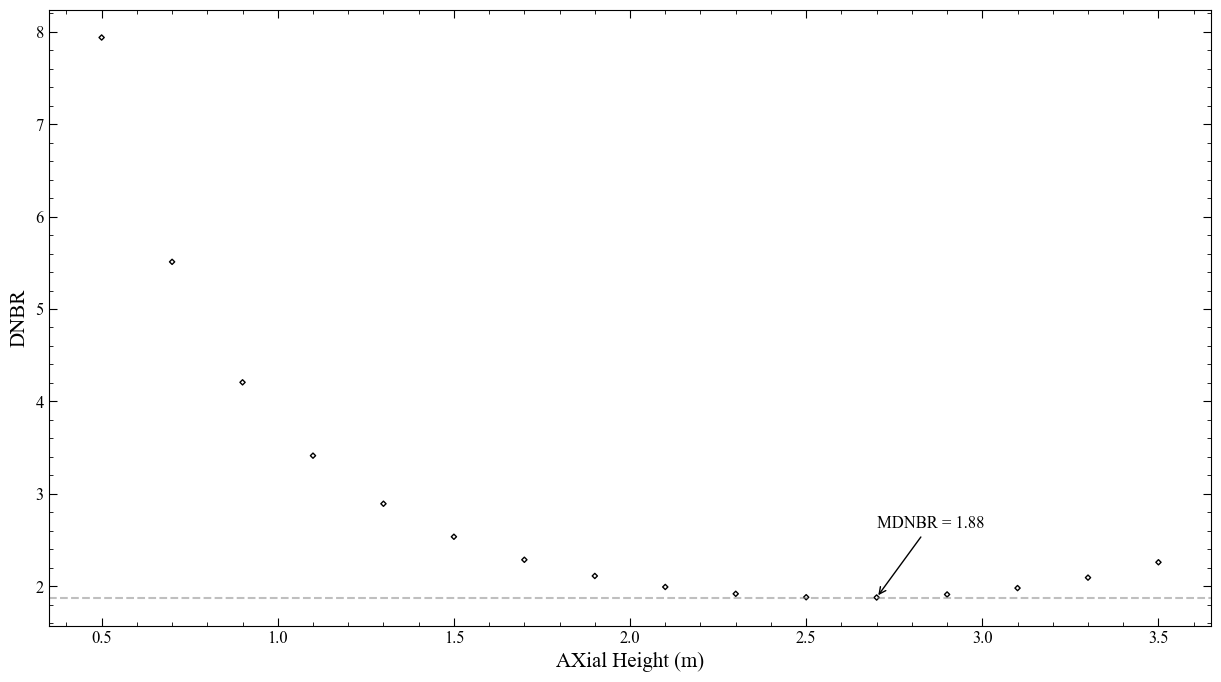

In [8]:
fig = plt.figure(figsize=(15, 8))

gs = fig.add_gridspec(
    1, 1,
    # height_ratios=[5, 2],
    hspace=0
)

ax_main = fig.add_subplot(gs[0])
# ax_res = fig.add_subplot(gs[1])


###########
# Main Axis
###########


ax_main.scatter(distance, dnbr,
            marker='D', color = primary_color, s = 7, facecolor = "none")

# ax_main.plot(resolved_x_range, dnbr_exp_fit,
#              linestyle = "--", color = primary_color, alpha = 0.3)

ax_main.axhline(np.min(dnbr), linestyle="--", color="grey", alpha=0.5)


ax_main.annotate(
    rf"MDNBR = {np.min(dnbr):.2f}",
    xy=(distance[np.argmin(dnbr)], np.min(dnbr)),
    xytext=(distance[np.argmin(dnbr)]*1, np.min(dnbr)*1.4),
    arrowprops=dict(arrowstyle="->", color="black", lw=1),
    color="black",
    fontsize=12
)



#####################
# Formatting and Save
#####################

ax_main.set_xlabel("AXial Height (m)")
ax_main.set_ylabel("DNBR")
# ax_res.set_ylabel("Residual")



for ax in [ax_main]:
    ax.minorticks_on()
    ax.tick_params(which='major', size=6, direction='in',
                   right=True, top=True)
    ax.tick_params(which='minor', size=3, direction='in',
                   right=True, top=True)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_bbox(dict(
            facecolor="white",
            edgecolor="none",
            pad=1.0
        ))

plt.savefig(
    r"C:\Users\sebas\Documents\Cambridge\NE2 Reactor Engineering\COBRA Project\Plots\PWR_DNBR_Plot.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()